In [6]:
#library for dataframe
import pandas as pd
#library for numerical operations
import numpy as np
#library for visualization
import matplotlib.pyplot as plt
#library for statistical visualization
import seaborn as sns
#library for handling missing values
from sklearn.impute import SimpleImputer, KNNImputer
#library for encoding categorical variables
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, MinMaxScaler, RobustScaler 
LabelEncoder, OneHotEncoder
#library for splitting the dataset into training and testing sets
from sklearn.model_selection import train_test_split
from scipy import stats

this code help us to display the first 5 rows of our dataset and gives information about each columns we remark that some columns contains missing values .

Partie A -> Exploration et détection des anomalies

In [7]:
# 1 -Chargement et aperçu du dataset
df = pd.read_csv("patients_data.csv")
display(df.head())
df.info()

,age,genre,tension_systolique,cholesterol,imc,fumeur,region,nb_visites,diagnostic
0,61.0,F,NaN,165.0,NaN,non,Alger,2,1
1,53.0,F,NaN,168.0,34.2,NaN,Blida,3,0
2,63.0,M,142.0,230.0,29.5,occasionnel,Constantine,1,1
3,73.0,F,124.0,192.0,95.0,régulier,Béjaïa,3,1
4,52.0,F,126.0,165.0,30.1,occasionnel,Constantine,5,1


<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   age                 470 non-null    float64
 1   genre               500 non-null    str    
 2   tension_systolique  468 non-null    float64
 3   cholesterol         469 non-null    float64
 4   imc                 464 non-null    float64
 5   fumeur              482 non-null    str    
 6   region              480 non-null    str    
 7   nb_visites          500 non-null    int64  
 8   diagnostic          500 non-null    int64  
dtypes: float64(4), int64(2), str(3)
memory usage: 35.3 KB


,age,tension_systolique,cholesterol,imc,nb_visites,diagnostic
count,470.000000,468.000000,469.000000,464.000000,500.000000,500.000000
mean,56.078723,124.467949,197.586354,27.379310,2.936000,0.470000
std,16.488808,24.199055,43.846999,7.034138,1.643565,0.499599
min,18.000000,5.000000,0.000000,15.000000,0.000000,0.000000
25%,47.000000,115.000000,178.000000,24.100000,2.000000,0.000000
50%,55.000000,124.000000,195.000000,27.000000,3.000000,0.000000
75%,63.000000,133.000000,213.000000,30.000000,4.000000,1.000000
max,200.000000,400.000000,800.000000,95.000000,8.000000,1.000000


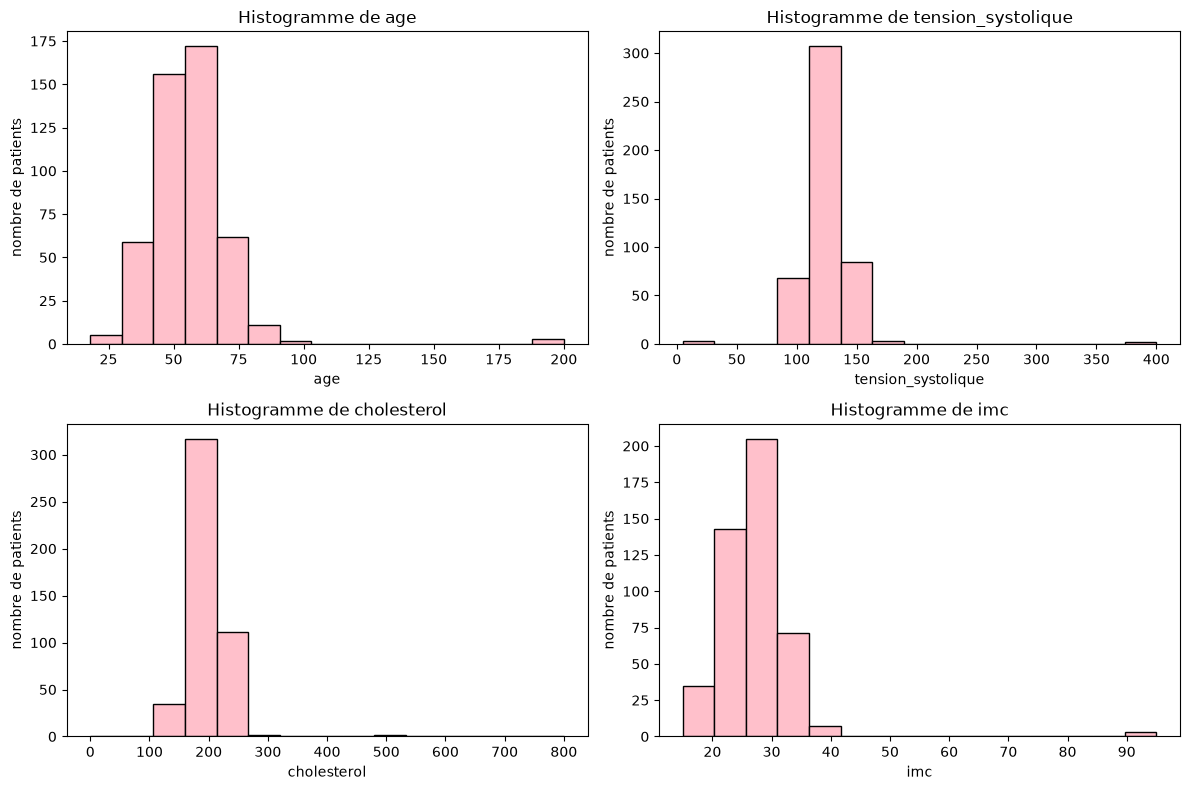

In [8]:
#2 — Statistiques descriptives et distributions 


display(df.describe())

# Les 4 variables numériques
variables = ['age', 'tension_systolique', 'cholesterol', 'imc']

# Créer une figure avec 2 lignes et 2 colonnes
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Parcourir les variables et les axes
for ax, var in zip(axes.flatten(), variables):
    ax.hist(df[var].dropna(), bins=15, edgecolor='black', color='pink')
    ax.set_title(f'Histogramme de {var}')
    ax.set_xlabel(var)
    ax.set_ylabel('nombre de patients')

# Ajuster l'espacement
plt.tight_layout()
plt.show()

histograms show someoutliers.
Age: approximately 200.
Systolic blood pressure: 400
Cholesterol: 500
BMI:90

age                   30
genre                  0
tension_systolique    32
cholesterol           31
imc                   36
fumeur                18
region                20
nb_visites             0
diagnostic             0
dtype: int64

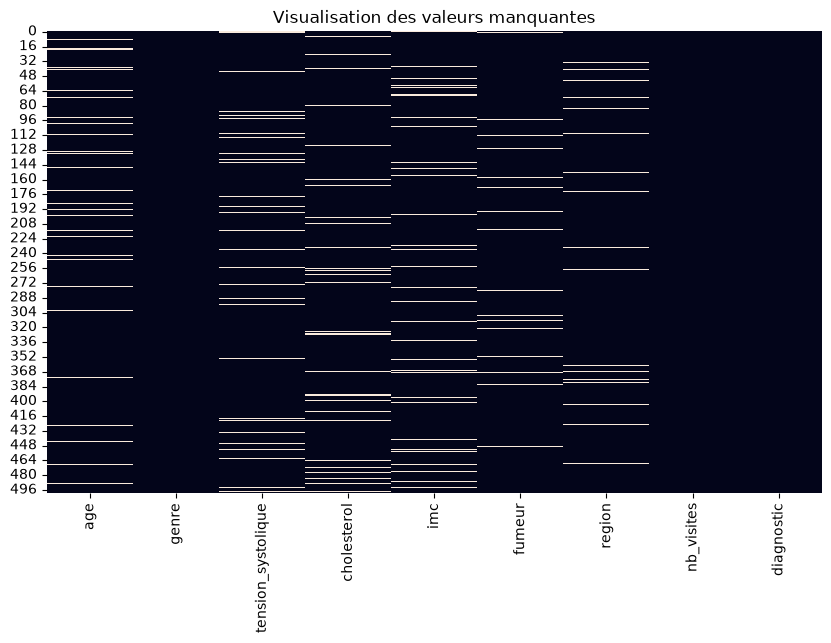

In [9]:
#Question 3 — Détection des valeurs manquantes 
display(df.isnull().sum())


plt.figure(figsize=(10, 6))
sns.heatmap(df.isnull(), cbar=False)
plt.title("Visualisation des valeurs manquantes")
plt.show()



partie B -> Nettoyage : valeurs manquantes et outliers

In [10]:
# Question 4 — Traitement des valeurs manquantes 

num_cols = ['age', 'tension_systolique', 'cholesterol', 'imc']
imp_num = SimpleImputer(strategy='median')
df[num_cols] = imp_num.fit_transform(df[num_cols])
# la moyenne est sensible aux valeurs extrêmes, donc on utilise la médiane parce qu'elle est plus robuste aux valeurs aberrantes.

# Pour les variables catégorielles, on peut utiliser la stratégie de l'imputation par la valeur la plus fréquente (mode) ou par la méthode KNN (K-Nearest Neighbors).
fumeur= SimpleImputer(strategy='most_frequent')
df[['fumeur']] = fumeur.fit_transform(df[['fumeur']])

#encoder la valeur region pour pouvoir l'utiliser dans la strategie KNN

# Encodage temporaire
codes, categories = pd.factorize(df['region'])
df['region_encoded'] = codes.astype(float)

# Remplacer -1 par NaN
df.loc[df['region_encoded'] == -1, 'region_encoded'] = np.nan

# Imputation KNN avec 5 voisins
imp_knn = KNNImputer(n_neighbors=5)
df[['region_encoded']] = imp_knn.fit_transform(df[['region_encoded']])

# Inverser l'encodage
df['region'] = categories[df['region_encoded'].round().astype(int)]

# Supprimer la colonne temporaire
df.drop(columns=['region_encoded'], inplace=True)

# utilise les informations des voisins les plus proches pour estimer les valeurs manquantes. Il peut donc mieux tenir compte des similarités entre patients

C:\Users\Afaf\AppData\Local\Temp\ipykernel_480\86334256.py:29: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=['region_encoded'], inplace=True)


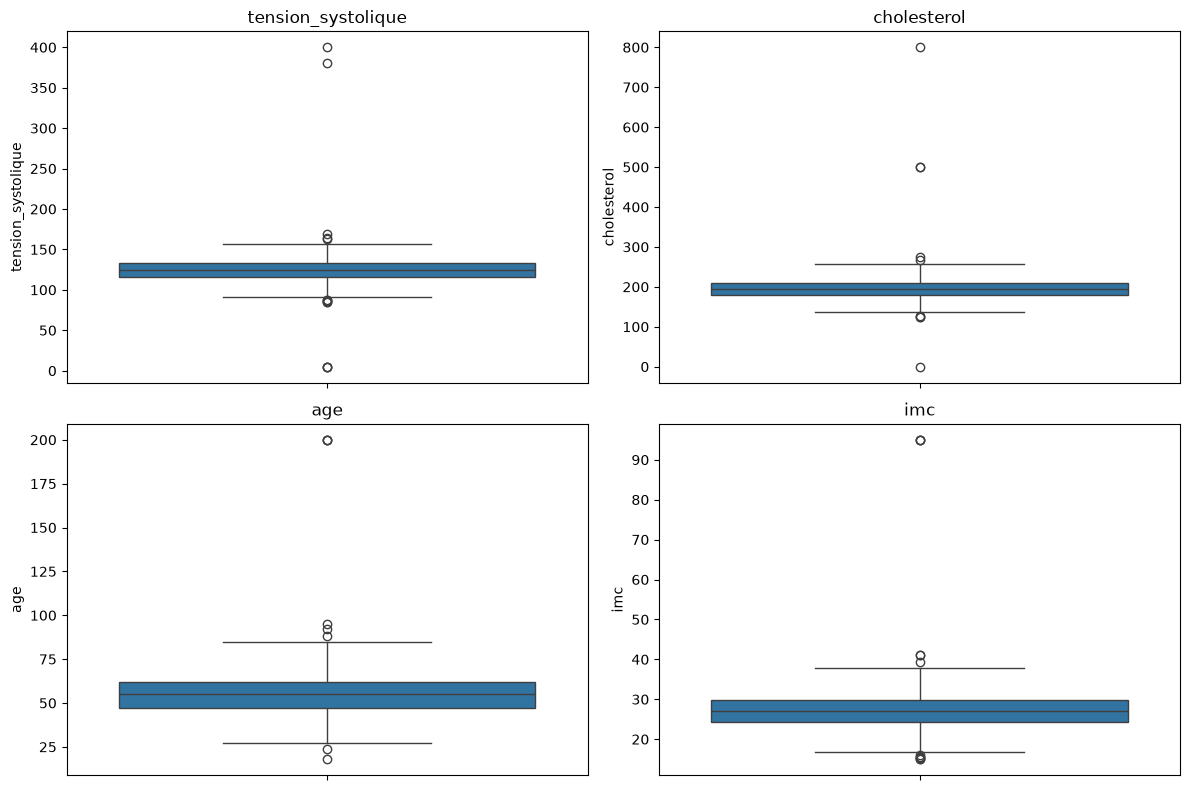

Nombre d'outliers (Z-score) : 4
Indices des outliers : [ 28  54 273 349]


In [11]:
#Question 5 — Détection des outliers 

cols = ['tension_systolique', 'cholesterol', 'age', 'imc']

plt.figure(figsize=(12, 8))

for i, col in enumerate(cols):
    plt.subplot(2, 2, i+1)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

#détection des outliers avec la méthode Z-score
z_scores = np.abs(stats.zscore(df['cholesterol']))
outliers_z = np.where(z_scores > 3)
print(f'Nombre d\'outliers (Z-score) : {len(outliers_z[0])}')

print("Indices des outliers :", outliers_z[0])

In [ ]:
# La méthode Z-score appliquée à la variable `cholesterol`, avec un seuil de |Z| > 3, a permis de détecter **4 valeurs aberrantes**, situées aux indices 28, 54, 273 et 349. Ces observations sont éloignées de plus de trois écarts-types de la moyenne. Elles doivent être examinées afin de déterminer s'il s'agit d'erreurs de saisie ou de valeurs médicalement inhabituelles.

In [ ]:
# question 6 :Traitement des outliers 